In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import re
import math

In [63]:
df_final= pd.read_excel('C:/Users/pc/Documents/my_thesis/research_data/new data/final_imp.xlsx')

In [64]:
# Keep the first occurrence of each MRN and remove subsequent duplicates
df_final = df_final.drop_duplicates(
    subset="MRN",
    keep="first"
).copy()

print("Remaining records:", len(df_final))
print("Removed records:", 6309 - len(df_final))
print("Remaining duplicated MRNs:", df_final["MRN"].duplicated().sum())

Remaining records: 5515
Removed records: 794
Remaining duplicated MRNs: 0


In [65]:
clinical_limits = {
    'hr': (30, 250),
    'sbp': (50, 300),
    'dbp': (20, 180),
    'rr': (5, 80),
    'temp': (30, 45),
    'spo2': (0, 100),
    'rbs': (20, 1000),
    'Pain_score': (0, 10),
    'sodium': (100, 180),
    'potassium': (1.5, 10),
    'wbc': (0.1, 300),
    'rbc': (0.5, 10),

    'basophil': (0, 20),
    'eosinophil': (0, 40),
    'monocyte': (0, 30),
    'neutrophil': (0, 100),
    'lymphocyte': (0, 100),
    'hemoglobin': (2, 25),
    'hematocrit': (5, 80),
    'mcv': (50, 150),
    'mch': (10, 50),
    'mchc': (20, 45),
    'mpv': (5, 20),
    'plt': (5, 2000),

    'ast_sgot': (0, 5000),
    'alt_sgpt': (0, 5000),
    'creatinine': (0.1, 20),

    'oxy_use': (0, 100),
    'Age_years': (13, 120)
}

# ==========================================
# Backup Original Dataset
# ==========================================
df_original = df_final.copy()

# ==========================================
# Replace Clinical Outliers with NaN
# ==========================================
print("Replacing values outside clinical limits...\n")

for col, (low, high) in clinical_limits.items():

    outliers = (df_final[col] < low) | (df_final[col] > high)
    n_outliers = outliers.sum()

    df_final.loc[outliers, col] = np.nan

Replacing values outside clinical limits...



In [66]:
df_final.rename(columns={"oxy_use": "oxygen_consumption"}, inplace=True)

In [67]:
df_final["oxygen_support"] = pd.cut(
    df_final["oxygen_consumption"],
    bins=[-float("inf"), 0, 8, 20, float("inf")],
    labels=[
        "Off oxygen",
        "Intranasal_O2_support",
        "Facemask O2_support",
        "Mechanical ventilation" ],
    right=True,
    include_lowest=True)

In [68]:

# Avoid division by zero
eps = 1e-6
# 3. Shock Index (SI)
df_final['Shock_Index'] = df_final['hr'] / (df_final['sbp'] + eps)
# Create WBC-Temperature interaction feature
df_final['WBC_Temperature_Interaction'] = df_final['wbc'] * df_final['temp']

In [69]:
# ============================================================
# REVERSE NUMERIC CODES BACK TO ORIGINAL CATEGORY NAMES
# ============================================================

# 1. Admission source
admit_reverse_map = {
    '1': 'Emergency',
    '2': 'Medical Ward',
    '3': 'Surgical Ward',
    '4': 'Pediatrics Ward',
    '5': 'Maternity Ward',
    '6': 'Orthopedic Ward',
    '7': 'HDU',
    '8': 'Other Specialty Wards'
}

df_final['Admission_source'] = (
    df_final['Admission_source']
    .astype(str)
    .replace(admit_reverse_map)
)


# 2. Diagnosis superclass
diag_reverse_map = {
    '1': 'Cardiovascular Disease',
    '2': 'Respiratory Disease',
    '3': 'Neurological Disease',
    '4': 'Sepsis / Infection',
    '5': 'Gastrointestinal / Hepatic Disease',
    '6': 'Trauma / Toxicology',
    '7': 'Endocrine / Metabolic Disease',
    '8': 'Renal Disease',
    '9': 'Thromboembolism',
    '10': 'Malignancy',
    '11': 'Multi-organ Failure',
    '12': 'Obstetric / Gynecology',
    '13': 'Autoimmune / Systemic Disease',
    '14': 'Other'
}

df_final['case_category'] = (
    df_final['case_category']
    .astype(str)
    .replace(diag_reverse_map)
)

# Continues variable categorization

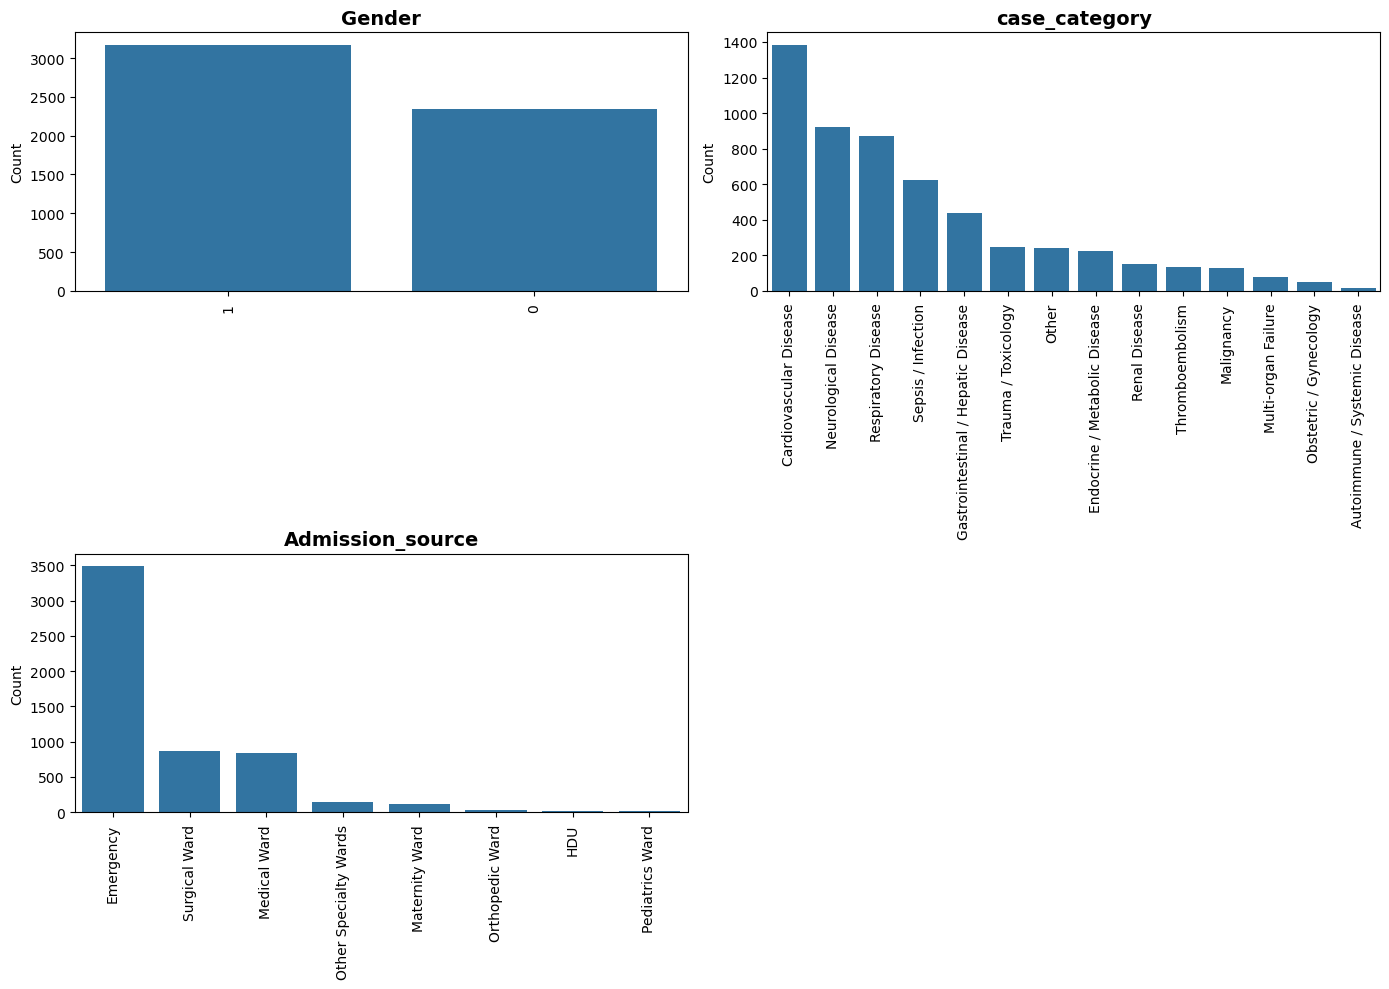

In [70]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

cat_var = ['Gender', 'case_category', 'Admission_source']

# Determine subplot layout
n = len(cat_var)
cols = 2
rows = math.ceil(n / cols)

# Create figure
fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(14, 10)
)

axes = axes.flatten()

# Plot each categorical variable
for i, var in enumerate(cat_var):

    # Order categories by frequency
    order = df_final[var].value_counts().index

    sns.countplot(
        data=df_final,
        x=var,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(
        var,
        fontsize=14,
        fontweight='bold'
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

    # Explicitly position labels directly under each bar
    axes[i].set_xticks(range(len(order)))
    axes[i].set_xticklabels(
        order,
        rotation=90,
        ha='center',
        va='top'
    )

    axes[i].tick_params(
        axis='x',
        pad=5
    )

# Hide unused subplot
for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [71]:
# KEEP ONLY SELECTED VARIABLES FOR MACHINE LEARNING
selected_columns = [
     'dbp',
    'Shock_Index',
    'spo2',
    'rbs',
    'sodium',
    'potassium',
    'neutrophil',
    'lymphocyte',
    'plt',
    'Admission_source',
    'case_category',
    'Age_years',
    'oxygen_support',
    'creatinine',
    'stat',
    'rr',
    'ast_sgot',
   'hemoglobin',
   'monocyte',
   'Pain_score',
    'WBC_Temperature_Interaction']
# Keep ONLY the selected columns that exist
df_final = df_final[
    [col for col in selected_columns if col in df_final.columns]
].copy()

In [72]:
df=df_final

In [73]:
# ============================================================
# CATEGORIZE CLINICAL VARIABLES BEFORE DATA SPLITTING
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# COPY FINAL DATASET
# ------------------------------------------------------------

df = df_final.copy()


# ------------------------------------------------------------
# CATEGORIZATION FUNCTION
# ------------------------------------------------------------

def categorize(df):
    # Diastolic Blood Pressure
    df['dbp'] = pd.cut(
        df['dbp'],
        [-float('inf'), 60, 90, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Respiratory Rate
    df['rr'] = pd.cut(
        df['rr'],
        [-float('inf'), 10, 25, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Oxygen Saturation
    df['spo2'] = pd.cut(
        df['spo2'],
        [-float('inf'), 90, float('inf')],
        labels=[0, 1]
    ).astype(float)

    # WBC × Temperature Interaction
    df['WBC_Temperature_Interaction'] = pd.cut(
        df['WBC_Temperature_Interaction'],
        [-float('inf'), 142, 454, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Sodium
    df['sodium'] = pd.cut(
        df['sodium'],
        [-float('inf'), 135, 146, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Potassium
    df['potassium'] = pd.cut(
        df['potassium'],
        [-float('inf'), 3.5, 5.1, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Random Blood Sugar
    df['rbs'] = pd.cut(
        df['rbs'],
        [-float('inf'), 70, 141, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Neutrophil
    df['neutrophil'] = pd.cut(
        df['neutrophil'],
        [-float('inf'), 1.5, 7.1, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Lymphocyte
    df['lymphocyte'] = pd.cut(
        df['lymphocyte'],
        [-float('inf'), 1, 4.1, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Monocyte
    df['monocyte'] = pd.cut(
        df['monocyte'],
        [-float('inf'), 0.2, 1.1, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Platelet
    df['plt'] = pd.cut(
        df['plt'],
        [-float('inf'), 150, 401, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Creatinine
    df['creatinine'] = pd.cut(
        df['creatinine'],
        [-float('inf'), 0.3, 1.21, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Shock Index
    # IMPORTANT: use Shock_Index itself, NOT WBC
    df['Shock_Index'] = pd.cut(
        df['Shock_Index'],
        [-float('inf'), 0.4, 0.8, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # AST/SGOT
    df['ast_sgot'] = pd.cut(
        df['ast_sgot'],
        [-float('inf'), 16, 60.1, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    # Hemoglobin
    df['hemoglobin'] = pd.cut(
        df['hemoglobin'],
        [-float('inf'), 11.2, 17.6, float('inf')],
        labels=[0, 1, 2]
    ).astype(float)

    return df

# ============================================================
# APPLY CATEGORIZATION BEFORE SPLITTING
# ============================================================

df_final = categorize(df)



In [74]:
from sklearn.model_selection import train_test_split

# ============================================================
# STRATIFIED 70/15/15 TRAIN–VALIDATION–TEST SPLIT
# Stratified by mortality outcome: stat
# ============================================================

random_state = 42

# 70% TRAIN, 30% remaining
train, remaining = train_test_split(
    df_final,
    test_size=0.30,
    stratify=df_final["stat"],
    random_state=random_state
)

# 15% VALIDATION, 15% TEST
validation, test = train_test_split(
    remaining,
    test_size=0.50,
    stratify=remaining["stat"],
    random_state=random_state
)

# ============================================================
# CHECK SIZES
# ============================================================

print("Dataset sizes:")
print(f"Train:      {len(train)} ({len(train)/len(df_final)*100:.2f}%)")
print(f"Validation: {len(validation)} ({len(validation)/len(df_final)*100:.2f}%)")
print(f"Test:       {len(test)} ({len(test)/len(df_final)*100:.2f}%)")

# ============================================================
# CHECK MORTALITY DISTRIBUTION
# ============================================================

for name, data in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}:")

    print(
        data["stat"]
        .value_counts()
        .sort_index()
        .rename(index={
            0: "low mortality risk",
            1: "High mortality risk"
        })
    )

    print(
        (data["stat"]
         .value_counts(normalize=True)
         .sort_index() * 100)
        .round(2)
        .rename(index={
            0: "low mortality risk",
            1: "High mortality risk"
        })
    )


Dataset sizes:
Train:      3860 (69.99%)
Validation: 827 (15.00%)
Test:       828 (15.01%)

Train:
stat
low mortality risk     2357
High mortality risk    1503
Name: count, dtype: int64
stat
low mortality risk     61.06
High mortality risk    38.94
Name: proportion, dtype: float64

Validation:
stat
low mortality risk     505
High mortality risk    322
Name: count, dtype: int64
stat
low mortality risk     61.06
High mortality risk    38.94
Name: proportion, dtype: float64

Test:
stat
low mortality risk     506
High mortality risk    322
Name: count, dtype: int64
stat
low mortality risk     61.11
High mortality risk    38.89
Name: proportion, dtype: float64


In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
mean_impute_cols = [
    'dbp',
    'WBC_Temperature_Interaction',
    'sodium',
    'potassium',
    'monocyte',
    'Age_years',
    'hemoglobin',
    'Shock_Index']
median_impute_cols = [
    'rr',
    'spo2',
    'rbs',
    'neutrophil',
    'lymphocyte',
    'plt',
    'creatinine',
    'Pain_score',
    'ast_sgot']
# CATEGORICAL VARIABLES — ONE-HOT ENCODING

categorical_cols = [
    'Admission_source',
    'case_category',
    'oxygen_support'
]

mean_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean'))
    ])
median_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ])

# CATEGORICAL IMPUTATION + ONE-HOT ENCODING

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False))  ])

# ============================================================
# COLUMN TRANSFORMER

preprocessor = ColumnTransformer(
    transformers=[
        ('mean_num', mean_transformer, mean_impute_cols),
        ('median_num', median_transformer, median_impute_cols),
        ('categorical', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

In [76]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier, plot_importance

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    brier_score_loss)
from sklearn.calibration import calibration_curve
print("Libraries imported successfully.")

Libraries imported successfully.


In [77]:
# Calculate class weight from training data only

negative_count = (train["stat"] == 0).sum()
positive_count = (train["stat"] == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training class distribution:")
print("Class 0 (Low mortality risk):", negative_count)
print("Class 1 (High mortality risk):", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Training class distribution:
Class 0 (Low mortality risk): 2357
Class 1 (High mortality risk): 1503
Scale Pos Weight: 1.5681969394544244


In [78]:
# XGBOOST MODEL DEFINITION

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",

    # Class imbalance
    scale_pos_weight=scale_pos_weight,

    # Anti-overfitting settings
    max_depth=3,
    min_child_weight=5,
    gamma=0.3,
    subsample=0.80,
    colsample_bytree=0.80,
    learning_rate=0.05,
    reg_alpha=0.5,
    reg_lambda=5
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=-1,
              num_parallel_tree=None, ...)


In [79]:
param_distributions = {
    "n_estimators": [
        100, 150, 200, 250, 300
    ],
    "max_depth": [
        2, 3, 4
    ],
    "learning_rate": [
        0.01, 0.03, 0.05, 0.08
    ],
    "min_child_weight": [
        3, 5, 7, 10
    ],
    "gamma": [
        0.1, 0.3, 0.5, 1.0
    ],
    "subsample": [
        0.70, 0.80, 0.90
    ],
    "colsample_bytree": [
        0.60, 0.70, 0.80, 0.90
    ],
    "reg_alpha": [
        0.1, 0.5, 1.0, 2.0
    ],
    "reg_lambda": [
        2, 5, 10, 20
    ]
}

print(
    "Number of parameters being optimized:",
    len(param_distributions)
)

Number of parameters being optimized: 9


In [80]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH
# TRAIN / VALIDATION / TEST APPROACH
# ============================================================

from itertools import product
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible parameter combinations
# ------------------------------------------------------------

param_combinations = list(product(
    param_distributions['n_estimators'],
    param_distributions['max_depth'],
    param_distributions['learning_rate'],
    param_distributions['min_child_weight'],
    param_distributions['gamma'],
    param_distributions['subsample'],
    param_distributions['colsample_bytree'],
    param_distributions['reg_alpha'],
    param_distributions['reg_lambda']
))

print("Total possible parameter combinations:", len(param_combinations))

Total possible parameter combinations: 184320


In [81]:
# ============================================================
# RANDOMLY SELECT 50 PARAMETER COMBINATIONS
# ============================================================

import random

random.seed(42)

n_iter = 50

selected_combinations = random.sample(
    param_combinations,
    n_iter
)

print("Number of parameter combinations to evaluate:", 
      len(selected_combinations))

Number of parameter combinations to evaluate: 50


In [82]:
X_train = train.drop(columns=["stat"])
y_train = train["stat"]

X_validation = validation.drop(columns=["stat"])
y_validation = validation["stat"]

X_test = test.drop(columns=["stat"])
y_test = test["stat"]

In [83]:
# ============================================================
# PREPROCESSING
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)

X_validation_processed = preprocessor.transform(X_validation)

X_test_processed = preprocessor.transform(X_test)

print("Train shape:", X_train_processed.shape)
print("Validation shape:", X_validation_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (3860, 40)
Validation shape: (827, 40)
Test shape: (828, 40)


In [84]:
# ============================================================
# XGBOOST HYPERPARAMETER EVALUATION
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

results = []

for i, combination in enumerate(selected_combinations, start=1):

    (
        n_estimators,
        max_depth,
        learning_rate,
        min_child_weight,
        gamma,
        subsample,
        colsample_bytree,
        reg_alpha,
        reg_lambda
    ) = combination

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,

        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        min_child_weight=min_child_weight,
        gamma=gamma,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda
    )

    # --------------------------------------------------------
    # Train ONLY on training data
    # --------------------------------------------------------

    model.fit(
        X_train_processed,
        y_train
    )

    # --------------------------------------------------------
    # Evaluate ONLY on validation data
    # --------------------------------------------------------

    y_validation_proba = model.predict_proba(
        X_validation_processed
    )[:, 1]

    validation_auc = roc_auc_score(
        y_validation,
        y_validation_proba
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "min_child_weight": min_child_weight,
        "gamma": gamma,
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,
        "validation_roc_auc": validation_auc
    })

    print(
        f"Combination {i}/{len(selected_combinations)} "
        f"- Validation ROC-AUC: {validation_auc:.4f}"
    )

print("\nHyperparameter search completed.")

Combination 1/50 - Validation ROC-AUC: 0.9340
Combination 2/50 - Validation ROC-AUC: 0.9267
Combination 3/50 - Validation ROC-AUC: 0.9120
Combination 4/50 - Validation ROC-AUC: 0.9376
Combination 5/50 - Validation ROC-AUC: 0.9192
Combination 6/50 - Validation ROC-AUC: 0.9332
Combination 7/50 - Validation ROC-AUC: 0.9300
Combination 8/50 - Validation ROC-AUC: 0.9082
Combination 9/50 - Validation ROC-AUC: 0.9360
Combination 10/50 - Validation ROC-AUC: 0.9372
Combination 11/50 - Validation ROC-AUC: 0.9297
Combination 12/50 - Validation ROC-AUC: 0.9291
Combination 13/50 - Validation ROC-AUC: 0.8979
Combination 14/50 - Validation ROC-AUC: 0.9085
Combination 15/50 - Validation ROC-AUC: 0.9095
Combination 16/50 - Validation ROC-AUC: 0.9293
Combination 17/50 - Validation ROC-AUC: 0.9292
Combination 18/50 - Validation ROC-AUC: 0.9320
Combination 19/50 - Validation ROC-AUC: 0.9351
Combination 20/50 - Validation ROC-AUC: 0.9315
Combination 21/50 - Validation ROC-AUC: 0.9112
Combination 22/50 - Va

In [85]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH RESULTS
# ============================================================

xgb_results_df = pd.DataFrame(results)

xgb_results_df = xgb_results_df.sort_values(
    by="validation_roc_auc",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 XGBoost Hyperparameter Combinations:")
display(xgb_results_df.head(10))


Top 10 XGBoost Hyperparameter Combinations:


,n_estimators,max_depth,learning_rate,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,validation_roc_auc
0,150,4,0.08,5,1.0,0.8,0.8,0.1,5,0.937605
1,250,4,0.05,7,0.1,0.8,0.9,0.5,2,0.937156
2,300,4,0.08,7,0.3,0.7,0.8,0.5,5,0.937126
3,150,4,0.08,7,1.0,0.9,0.7,2.0,10,0.936160
4,300,4,0.03,7,1.0,0.9,0.9,0.1,2,0.936049
5,250,4,0.05,7,0.1,0.7,0.6,0.5,5,0.935484
6,250,3,0.08,3,0.3,0.9,0.9,1.0,20,0.935145
7,300,3,0.08,5,1.0,0.7,0.9,1.0,20,0.934961
8,200,4,0.08,10,0.1,0.9,0.7,0.5,10,0.934506
9,300,4,0.08,10,0.3,0.8,0.8,1.0,2,0.934451


In [86]:
# BEST XGBOOST HYPERPARAMETERS
xgb_best_row = xgb_results_df.iloc[0]
xgb_best_params = {
    "n_estimators": int(xgb_best_row["n_estimators"]),
    "max_depth": int(xgb_best_row["max_depth"]),
    "learning_rate": xgb_best_row["learning_rate"],
    "min_child_weight": int(xgb_best_row["min_child_weight"]),
    "gamma": xgb_best_row["gamma"],
    "subsample": xgb_best_row["subsample"],
    "colsample_bytree": xgb_best_row["colsample_bytree"],
    "reg_alpha": xgb_best_row["reg_alpha"],
    "reg_lambda": xgb_best_row["reg_lambda"]
}

xgb_best_val_auc = xgb_best_row["validation_roc_auc"]

print("Best XGBoost Parameters:")
for parameter, value in xgb_best_params.items():
    print(f"  {parameter}: {value}")

print(f"\nBest XGBoost Validation ROC-AUC: {xgb_best_val_auc:.4f}")

Best XGBoost Parameters:
  n_estimators: 150
  max_depth: 4
  learning_rate: 0.08
  min_child_weight: 5
  gamma: 1.0
  subsample: 0.8
  colsample_bytree: 0.8
  reg_alpha: 0.1
  reg_lambda: 5.0

Best XGBoost Validation ROC-AUC: 0.9376


In [87]:
# ============================================================
# FINAL XGBOOST MODEL — TEST SET PREDICTIONS
# ============================================================

from xgboost import XGBClassifier

# Create final XGBoost model using the best hyperparameters
xgb_final = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

# Train using training data only
xgb_final.fit(
    X_train_processed,
    y_train
)

# ------------------------------------------------------------
# Test-set probability predictions
# ------------------------------------------------------------

xgb_test_proba = xgb_final.predict_proba(
    X_test_processed
)[:, 1]

# ------------------------------------------------------------
# Convert probabilities to binary predictions
# 0 = Survived
# 1 = Died
# ------------------------------------------------------------

xgb_test_pred = (xgb_test_proba >= 0.5).astype(int)

print("Final XGBoost model trained successfully.")
print("Test predictions generated.")
print("Number of test predictions:", len(xgb_test_pred))

Final XGBoost model trained successfully.
Test predictions generated.
Number of test predictions: 828


In [88]:

# FINAL XGBOOST MODEL

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("Final XGBoost model fitted successfully.")

Final XGBoost model fitted successfully.


In [89]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("Final XGBoost model fitted successfully.")

Final XGBoost model fitted successfully.


In [90]:
# Binary prediction: 0 = survived, 1 = died
xgb_test_pred = xgb_model.predict(
    X_test_processed)
# Probability of death (class 1)
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed)[:, 1]
print("Test predictions generated successfully.")
print("Number of test cases:", len(xgb_test_pred))

Test predictions generated successfully.
Number of test cases: 828


In [91]:
# FINAL XGBOOST TEST PREDICTIONS AND PROBABILITIES
# Class prediction
xgb_test_pred = xgb_model.predict(
    X_test_processed
)

# Mortality probability
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", len(xgb_test_pred))
print("Probabilities:", len(xgb_test_prob))

Predictions: 828
Probabilities: 828


In [92]:
# ============================================================
# FINAL XGBOOST TEST-SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report
)

# ============================================================
# TRAINING-SET AUROC
# ============================================================

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]

xgb_train_roc_auc = roc_auc_score(
    y_train,
    xgb_train_prob
)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# OVERALL TEST-SET PERFORMANCE
# ============================================================

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_sensitivity = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

# Brier Score
xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob
)


# ============================================================
# AUROC GAP
# ============================================================

xgb_auc_gap = xgb_train_roc_auc - xgb_test_roc_auc


# ============================================================
# FINAL REPORT
# ============================================================

print("\nXGBoost Performance")
print("=" * 60)

print(f"Training AUROC: {xgb_train_roc_auc:.4f}")
print(f"Test AUROC:     {xgb_test_roc_auc:.4f}")
print(f"AUROC Gap:      {xgb_auc_gap:.4f}")

print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {xgb_test_accuracy:.4f}")
print(f"Precision:      {xgb_test_precision:.4f}")
print(f"Sensitivity:    {xgb_test_sensitivity:.4f}")
print(f"F1-score:       {xgb_test_f1:.4f}")
print(f"Brier Score:    {xgb_test_brier:.4f}")

print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        xgb_test_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


XGBoost Performance
Training AUROC: 0.9500
Test AUROC:     0.9094
AUROC Gap:      0.0406

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.8406
Precision:      0.8084
Sensitivity:    0.7733
F1-score:       0.7905
Brier Score:    0.1152

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.8596    0.8834    0.8713       506
        Died     0.8084    0.7733    0.7905       322

    accuracy                         0.8406       828
   macro avg     0.8340    0.8283    0.8309       828
weighted avg     0.8397    0.8406    0.8399       828



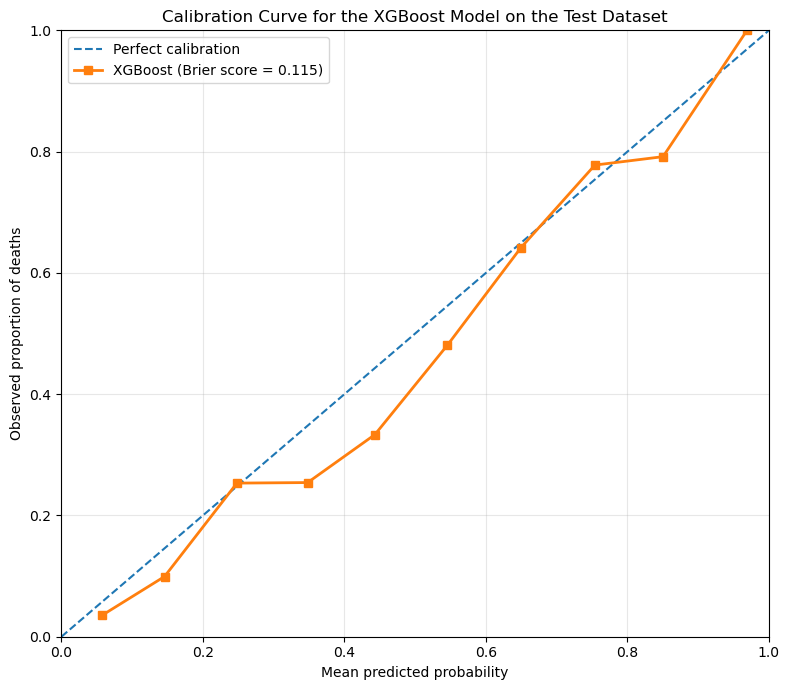

In [33]:
# ============================================================
# XGBOOST CALIBRATION CURVE — TEST DATASET
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


# Calibration data
xgb_prob_true_test, xgb_prob_pred_test = calibration_curve(
    y_test,
    xgb_test_prob,
    n_bins=10,
    strategy="uniform"
)


# Brier score
xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob)

# Plot
plt.figure(figsize=(8, 7))
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration")

plt.plot(
    xgb_prob_pred_test,
    xgb_prob_true_test,
    marker="s",
    linewidth=2,
    markersize=6,
    label=f"XGBoost (Brier score = {xgb_test_brier:.3f})"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed proportion of deaths")

plt.title(
    "Calibration Curve for the XGBoost Model on the Test Dataset"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# CLEAN SHAP FEATURE NAMES FOR DISPLAY
# ============================================================

# Get original processed feature names
feature_names_raw = preprocessor.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = (
    pd.Series(feature_names_raw)
    .str.replace("mean_num__", "", regex=False)
    .str.replace("median_num__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .tolist()
)

print("Cleaned feature names:")
print(feature_names)

Cleaned feature names:
['dbp', 'WBC_Temperature_Interaction', 'sodium', 'potassium', 'monocyte', 'Age_years', 'hemoglobin', 'Shock_Index', 'rr', 'spo2', 'rbs', 'neutrophil', 'lymphocyte', 'plt', 'creatinine', 'Pain_score', 'ast_sgot', 'Admission_source_HDU', 'Admission_source_Maternity Ward', 'Admission_source_Medical Ward', 'Admission_source_Orthopedic Ward', 'Admission_source_Other Specialty Wards', 'Admission_source_Pediatrics Ward', 'Admission_source_Surgical Ward', 'case_category_Cardiovascular Disease', 'case_category_Endocrine / Metabolic Disease', 'case_category_Gastrointestinal / Hepatic Disease', 'case_category_Malignancy', 'case_category_Multi-organ Failure', 'case_category_Neurological Disease', 'case_category_Obstetric / Gynecology', 'case_category_Other', 'case_category_Renal Disease', 'case_category_Respiratory Disease', 'case_category_Sepsis / Infection', 'case_category_Thromboembolism', 'case_category_Trauma / Toxicology', 'oxygen_support_Intranasal_O2_support', 'oxyge

SHAP values shape: (828, 40)
Test data shape: (828, 40)
Number of feature names: 40

TOP 20 SHAP FEATURES
                              Feature  Mean_ABS_SHAP
                               sodium       0.707698
                            potassium       0.542188
          WBC_Temperature_Interaction       0.362257
                          Shock_Index       0.311620
                            Age_years       0.287333
            oxygen_support_Off oxygen       0.268521
oxygen_support_Mechanical ventilation       0.260851
 case_category_Cardiovascular Disease       0.241181
        Admission_source_Medical Ward       0.215075
                                  dbp       0.194154
                           Pain_score       0.171792
                                 spo2       0.158419
                           lymphocyte       0.130694
                             ast_sgot       0.113789
 oxygen_support_Intranasal_O2_support       0.096628
                           creatinine       0.

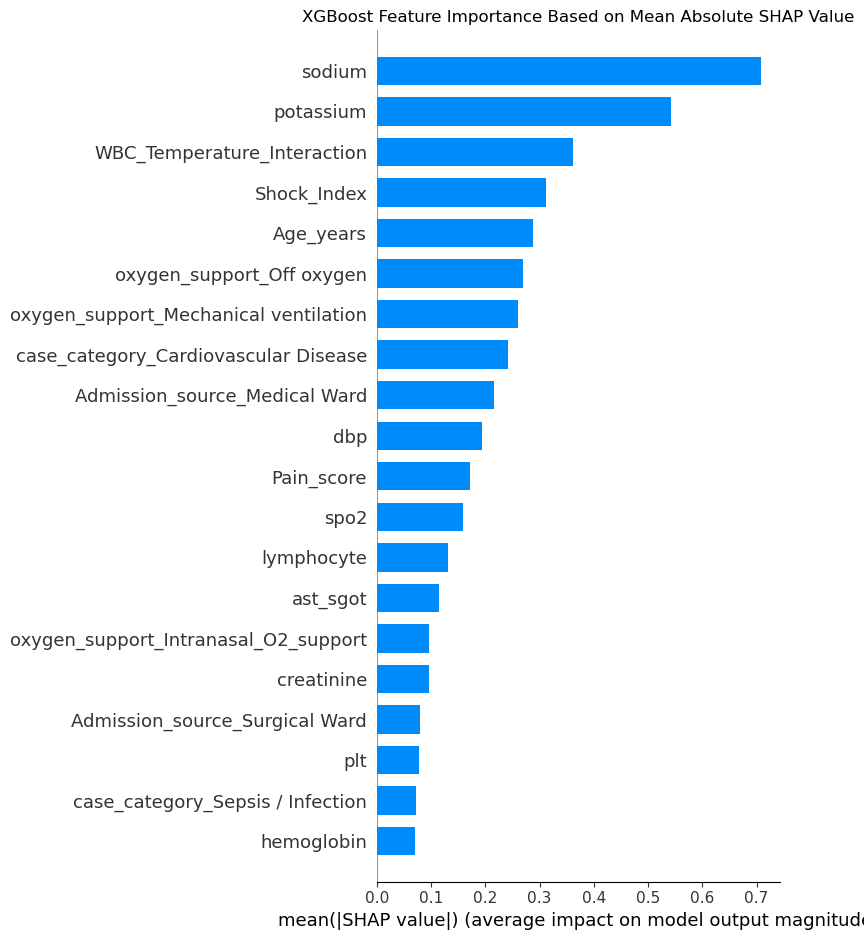

In [35]:
# ============================================================
# SHAP FEATURE IMPORTANCE — FINAL XGBOOST MODEL
# ============================================================

import shap
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create SHAP explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values on the TEST SET
shap_values = explainer.shap_values(X_test_processed)

print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test_processed.shape)


# ------------------------------------------------------------
# 2. Get and CLEAN processed feature names
# ------------------------------------------------------------

feature_names_raw = preprocessor.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = [
    name.replace("mean_num__", "")
        .replace("median_num__", "")
        .replace("categorical__", "")
    for name in feature_names_raw
]

print("Number of feature names:", len(feature_names))


# ------------------------------------------------------------
# 3. SHAP feature importance
# ------------------------------------------------------------

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_ABS_SHAP": abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
)

print("\nTOP 20 SHAP FEATURES")
print("=" * 60)
print(shap_importance.head(20).to_string(index=False))


# ------------------------------------------------------------
# 4. SHAP BAR PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "XGBoost Feature Importance Based on Mean Absolute SHAP Value"
)

plt.tight_layout()
plt.show()

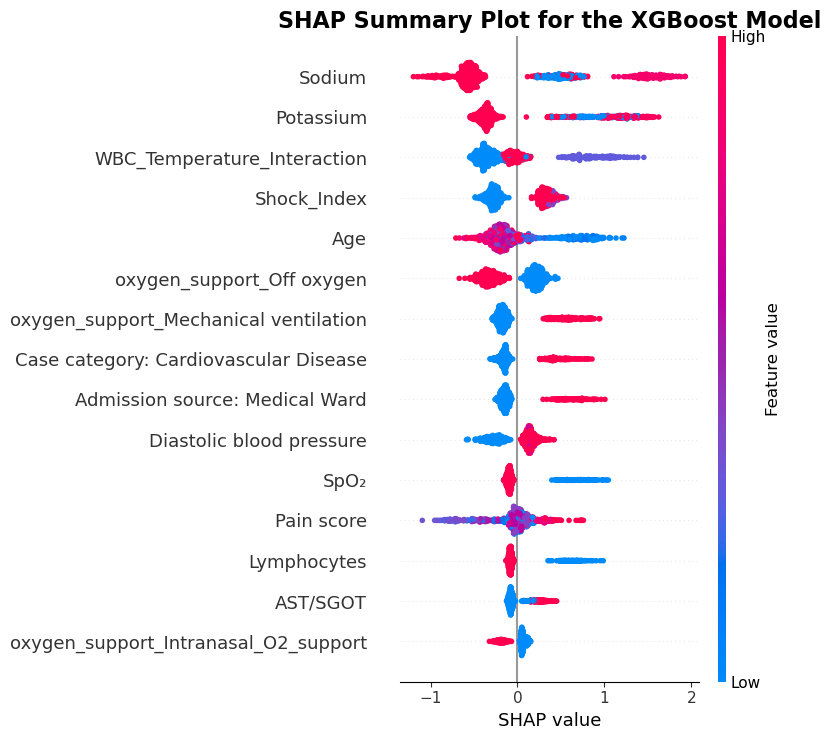

In [36]:
# ============================================================
# XGBOOST SHAP BEESWARM PLOT — TOP 15 VARIABLES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. Validation data
# ------------------------------------------------------------

X_shap = np.asarray(X_validation_processed)

# ------------------------------------------------------------
# 2. Get feature names
# ------------------------------------------------------------

feature_names = preprocessor.get_feature_names_out()

# ------------------------------------------------------------
# 3. Remove preprocessing prefixes
# ------------------------------------------------------------

feature_names = [
    str(x)
    .replace("mean_num__", "")
    .replace("median_num__", "")
    .replace("categorical__", "")
    for x in feature_names
]

# ------------------------------------------------------------
# 4. Clinical variable names
# ------------------------------------------------------------

name_map = {
    "hr": "Heart rate",
    "sbp": "Systolic blood pressure",
    "dbp": "Diastolic blood pressure",
    "temp": "Temperature",
    "spo2": "SpO₂",
    "rbs": "Random blood sugar",
    "sodium": "Sodium",
    "potassium": "Potassium",
    "neutrophil": "Neutrophils",
    "lymphocyte": "Lymphocytes",
    "plt": "Platelet count",
    "Age_years": "Age",
    "oxy_use": "Oxygen use",
    "creatinine": "Creatinine",
    "rr": "Respiratory rate",
    "ast_sgot": "AST/SGOT",
    "hemoglobin": "Hemoglobin",
    "monocyte": "Monocytes",
    "Pain_score": "Pain score",
    "wbc": "White blood cell count"
}

clean_names = []

for name in feature_names:

    if name in name_map:
        name = name_map[name]

    elif name.startswith("Admission_source_"):
        name = name.replace(
            "Admission_source_",
            "Admission source: "
        )

    elif name.startswith("case_category_"):
        name = name.replace(
            "case_category_",
            "Case category: "
        )

    clean_names.append(name)

# ------------------------------------------------------------
# 5. SHAP dataframe
# ------------------------------------------------------------

X_shap_df = pd.DataFrame(
    X_shap,
    columns=clean_names
)

# ------------------------------------------------------------
# 6. Calculate SHAP values
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_shap_df
)

# ------------------------------------------------------------
# 7. Handle binary classification
# ------------------------------------------------------------

if isinstance(shap_values, list):

    shap_values = shap_values[1]

elif (
    isinstance(shap_values, np.ndarray)
    and shap_values.ndim == 3
):

    shap_values = shap_values[:, :, 1]

# ------------------------------------------------------------
# 8. TOP 15 SHAP BEESWARM
# ------------------------------------------------------------

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    shap_values,
    X_shap_df,
    plot_type="dot",
    max_display=15,
    color_bar=True,
    show=False
)

plt.title(
    "SHAP Summary Plot for the XGBoost Model",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "SHAP value",
    fontsize=13
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. Save high-resolution figure
# ------------------------------------------------------------

plt.savefig(
    "XGBoost_SHAP_Top15_Validation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "XGBoost_SHAP_Top15_Validation.pdf",
    bbox_inches="tight"
)

plt.show()


# Random forest model

In [93]:
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [94]:
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [95]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH SPACE
# ============================================================

rf_param_grid = {

    'n_estimators': [
        200, 300, 500
    ],

    'max_depth': [
        5, 8, 10, 12, 15
    ],

    'min_samples_split': [
        5, 10, 15, 20
    ],

    'min_samples_leaf': [
        2, 4, 6, 8
    ],

    'max_features': [
        'sqrt', 'log2'
    ],

    'bootstrap': [
        True
    ],

    'criterion': [
        'gini', 'entropy'
    ]
}

In [96]:
# ============================================================
# 11. RANDOMIZED HYPERPARAMETER SEARCH USING VALIDATION SET
# ============================================================

import itertools
import random
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible hyperparameter combinations
# ------------------------------------------------------------

rf_all_combinations = list(
    itertools.product(
        rf_param_grid['n_estimators'],
        rf_param_grid['max_depth'],
        rf_param_grid['min_samples_split'],
        rf_param_grid['min_samples_leaf'],
        rf_param_grid['max_features'],
        rf_param_grid['bootstrap'],
        rf_param_grid['criterion']
    )
)

# ------------------------------------------------------------
# Randomly select 50 combinations
# ------------------------------------------------------------

random.seed(42)

rf_sampled_combinations = random.sample(
    rf_all_combinations,
    50
)

print(
    f"Total possible combinations: "
    f"{len(rf_all_combinations):,}"
)

print(
    f"Randomly selected combinations: "
    f"{len(rf_sampled_combinations)}"
)

# ------------------------------------------------------------
# Evaluate each combination on validation set
# ------------------------------------------------------------

rf_results = []

for combination in rf_sampled_combinations:

    rf_params = {
        'n_estimators': combination[0],
        'max_depth': combination[1],
        'min_samples_split': combination[2],
        'min_samples_leaf': combination[3],
        'max_features': combination[4],
        'bootstrap': combination[5],
        'criterion': combination[6]
    }

    rf_candidate = RandomForestClassifier(
        **rf_params,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    # Train ONLY on training data
    rf_candidate.fit(
        X_train_processed,
        y_train
    )

    # Predict probabilities on validation data
    rf_val_prob_candidate = rf_candidate.predict_proba(
        X_validation_processed
    )[:, 1]

    # Validation ROC-AUC
    rf_val_auc_candidate = roc_auc_score(
        y_validation,
        rf_val_prob_candidate
    )

    rf_results.append({
        **rf_params,
        'validation_roc_auc': rf_val_auc_candidate
    })

# ------------------------------------------------------------
# Store and rank results
# ------------------------------------------------------------

rf_results_df = pd.DataFrame(
    rf_results
)

rf_results_df = rf_results_df.sort_values(
    by='validation_roc_auc',
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Random Forest Hyperparameter Combinations:")
display(
    rf_results_df.head(10)
)

Total possible combinations: 960
Randomly selected combinations: 50

Top 10 Random Forest Hyperparameter Combinations:


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,criterion,validation_roc_auc
0,500,15,10,2,sqrt,True,entropy,0.934918
1,200,12,15,2,sqrt,True,entropy,0.932550
2,300,12,5,4,sqrt,True,entropy,0.930281
3,200,10,15,2,log2,True,entropy,0.930041
4,500,12,20,6,log2,True,gini,0.929709
5,200,12,15,4,sqrt,True,gini,0.929512
6,200,12,20,6,log2,True,gini,0.929482
7,500,10,5,6,sqrt,True,entropy,0.928756
8,200,15,10,6,sqrt,True,entropy,0.928744
9,500,10,20,6,sqrt,True,entropy,0.928522


In [97]:
# ============================================================
# 12. SELECT BEST RANDOM FOREST HYPERPARAMETERS
# ============================================================

rf_best_row = rf_results_df.iloc[0]

rf_best_params = {
    'n_estimators': int(rf_best_row['n_estimators']),
    'max_depth': int(rf_best_row['max_depth']),
    'min_samples_split': int(rf_best_row['min_samples_split']),
    'min_samples_leaf': int(rf_best_row['min_samples_leaf']),
    'max_features': rf_best_row['max_features'],
    'bootstrap': bool(rf_best_row['bootstrap']),
    'criterion': rf_best_row['criterion']
}

rf_best_val_auc = rf_best_row['validation_roc_auc']

print("Random Forest — Best Validation ROC-AUC:")
print(f"{rf_best_val_auc:.4f}")

print("\nRandom Forest — Best Parameters:")
for parameter, value in rf_best_params.items():
    print(f"  {parameter}: {value}")

Random Forest — Best Validation ROC-AUC:
0.9349

Random Forest — Best Parameters:
  n_estimators: 500
  max_depth: 15
  min_samples_split: 10
  min_samples_leaf: 2
  max_features: sqrt
  bootstrap: True
  criterion: entropy


In [98]:
# ============================================================
# SELECT BEST RANDOM FOREST HYPERPARAMETERS
# ============================================================

rf_best_row = rf_results_df.iloc[0]

rf_best_params = {
    'n_estimators': int(rf_best_row['n_estimators']),
    'max_depth': int(rf_best_row['max_depth']),
    'min_samples_split': int(rf_best_row['min_samples_split']),
    'min_samples_leaf': int(rf_best_row['min_samples_leaf']),
    'max_features': rf_best_row['max_features'],
    'bootstrap': bool(rf_best_row['bootstrap']),
    'criterion': rf_best_row['criterion']
}

In [99]:
# ============================================================
# RANDOM FOREST — FINAL MODEL TRAINING
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    **rf_best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model fitted successfully.")

Random Forest model fitted successfully.


In [100]:
# ============================================================
# RANDOM FOREST FINAL TEST-SET PERFORMANCE
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# TRAIN FINAL RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    **rf_best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)


# ============================================================
# TRAINING AUROC
# ============================================================

rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]

rf_train_roc_auc = roc_auc_score(
    y_train,
    rf_train_prob
)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

rf_test_pred = rf_model.predict(
    X_test_processed
)

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# OVERALL TEST-SET PERFORMANCE
# ============================================================

rf_test_accuracy = accuracy_score(
    y_test,
    rf_test_pred
)

rf_test_precision = precision_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_sensitivity = recall_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_f1 = f1_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_roc_auc = roc_auc_score(
    y_test,
    rf_test_prob
)

rf_test_brier = brier_score_loss(
    y_test,
    rf_test_prob
)


# ============================================================
# SPECIFICITY
# ============================================================

rf_test_tn, rf_test_fp, rf_test_fn, rf_test_tp = confusion_matrix(
    y_test,
    rf_test_pred
).ravel()

rf_test_specificity = rf_test_tn / (
    rf_test_tn + rf_test_fp
)


# ============================================================
# AUROC GAP
# ============================================================

rf_auc_gap = rf_train_roc_auc - rf_test_roc_auc


# ============================================================
# FINAL REPORT
# ============================================================

print("\nRandom Forest Performance")
print("=" * 60)

print(f"Training AUROC: {rf_train_roc_auc:.4f}")
print(f"Test AUROC:     {rf_test_roc_auc:.4f}")
print(f"AUROC Gap:      {rf_auc_gap:.4f}")

print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {rf_test_accuracy:.4f}")
print(f"Precision:      {rf_test_precision:.4f}")
print(f"Sensitivity:    {rf_test_sensitivity:.4f}")
print(f"Specificity:    {rf_test_specificity:.4f}")
print(f"F1-score:       {rf_test_f1:.4f}")
print(f"Brier Score:    {rf_test_brier:.4f}")

print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


Random Forest Performance
Training AUROC: 0.9807
Test AUROC:     0.9087
AUROC Gap:      0.0720

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.8357
Precision:      0.8394
Sensitivity:    0.7143
Specificity:    0.9130
F1-score:       0.7718
Brier Score:    0.1205

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.8339    0.9130    0.8717       506
        Died     0.8394    0.7143    0.7718       322

    accuracy                         0.8357       828
   macro avg     0.8367    0.8137    0.8218       828
weighted avg     0.8361    0.8357    0.8329       828



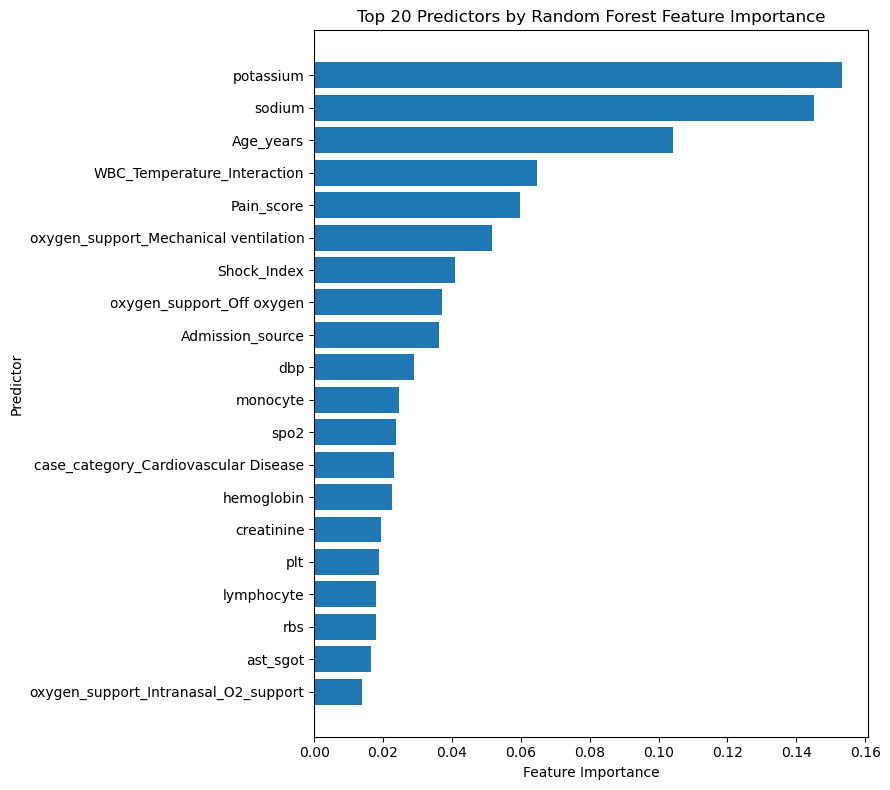

In [101]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE — TOP 20
# ORIGINAL PREDICTOR NAMES ONLY
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. GET FEATURE NAMES AND RANDOM FOREST IMPORTANCE
# ------------------------------------------------------------

rf_feature_names = preprocessor.get_feature_names_out()
rf_importances = rf_model.feature_importances_

rf_feature_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# ------------------------------------------------------------
# 2. REMOVE PREPROCESSING PREFIXES
#    Examples:
#    mean_num__temp       -> temp
#    median_num__hr       -> hr
#    cat__Admission_source_Emergency -> Admission_source_Emergency
# ------------------------------------------------------------

rf_feature_importance_df["Feature"] = (
    rf_feature_importance_df["Feature"]
    .str.split("__", n=1)
    .str[-1]
)

# ------------------------------------------------------------
# 3. COMBINE ONE-HOT CATEGORIES INTO ORIGINAL PREDICTOR
# ------------------------------------------------------------

rf_categorical_features = [
    "oxy_use",
    "Admission_source",
    "diag_superclass"
]

for variable in rf_categorical_features:

    rf_feature_importance_df.loc[
        rf_feature_importance_df["Feature"].str.startswith(
            variable + "_"
        ),
        "Feature"
    ] = variable

# ------------------------------------------------------------
# 4. COMBINE IMPORTANCE FOR EACH ORIGINAL PREDICTOR
# ------------------------------------------------------------

rf_feature_importance_df = (
    rf_feature_importance_df
    .groupby("Feature", as_index=False)["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. SELECT TOP 20 PREDICTORS
# ------------------------------------------------------------

rf_top20 = (
    rf_feature_importance_df
    .head(20)
    .sort_values(
        "Importance",
        ascending=True
    )
)
# ------------------------------------------------------------
# 6. PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 8))

plt.barh(
    rf_top20["Feature"],
    rf_top20["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")

plt.title(
    "Top 20 Predictors by Random Forest Feature Importance"
)

plt.tight_layout()
plt.show()

# Suport Vector Machine(SVM and logistic regresion

In [102]:
 from sklearn.preprocessing import StandardScaler

# ============================================================
# STANDARDIZATION FOR SVM AND LOGISTIC REGRESSION
# ============================================================

# Initialize scaler
scaler = StandardScaler()

# ------------------------------------------------------------
# 1. FIT SCALER ONLY ON TRAINING DATA
# ------------------------------------------------------------
X_train_scaled = scaler.fit_transform(X_train_processed)

# ------------------------------------------------------------
# 2. APPLY TRAINING-LEARNED SCALER TO VALIDATION DATA
# ------------------------------------------------------------
X_validation_scaled = scaler.transform(X_validation_processed)

# ------------------------------------------------------------
# 3. APPLY TRAINING-LEARNED SCALER TO TEST DATA
# ------------------------------------------------------------
X_test_scaled = scaler.transform(X_test_processed)

# ============================================================
# CHECK SHAPES
# ============================================================

print("Standardized dataset shapes:")
print("-" * 45)
print("Training   :", X_train_scaled.shape)
print("Validation :", X_validation_scaled.shape)
print("Test       :", X_test_scaled.shape)

Standardized dataset shapes:
---------------------------------------------
Training   : (3860, 40)
Validation : (827, 40)
Test       : (828, 40)


In [103]:
# ============================================================
# SUPPORT VECTOR MACHINE (SVM) — MODEL DEFINITION
# ============================================================

from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    class_weight='balanced',
    random_state=42
)

print(svm_model)

SVC(class_weight='balanced', probability=True, random_state=42)


In [104]:
# ============================================================
# SVM — HYPERPARAMETER SEARCH SPACE
# ============================================================

svm_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    'gamma': [
        'scale',
        0.001,
        0.01,
        0.1,
        1
    ],

    'kernel': [
        'rbf'
    ]
}

print("SVM hyperparameter search space:")
print(svm_param_grid)

SVM hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1, 1], 'kernel': ['rbf']}


In [105]:

from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from itertools import product

In [106]:
# ============================================================
# SVM — HYPERPARAMETER TUNING USING VALIDATION SET
# ============================================================




# ============================================================
# 1. GENERATE PARAMETER COMBINATIONS
# ============================================================

param_combinations = list(product(
    svm_param_grid['C'],
    svm_param_grid['gamma'],
    svm_param_grid['kernel']
))


# ============================================================
# 2. EVALUATE EACH COMBINATION
# ============================================================

svm_results = []

for C, gamma, kernel in param_combinations:

    svm_candidate = SVC(
        C=C,
        gamma=gamma,
        kernel=kernel,
        probability=True,
        class_weight='balanced',
        random_state=42
    )

    # Fit ONLY on training data
    svm_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = svm_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    svm_results.append({
        'C': C,
        'gamma': gamma,
        'kernel': kernel,
        'Validation_ROC_AUC': validation_auc
    })


# ============================================================
# 3. RESULTS TABLE
# ============================================================

svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)


print("SVM hyperparameter tuning results:")
print(svm_results_df)


# ============================================================
# 4. BEST HYPERPARAMETERS
# ============================================================

best_svm_params = svm_results_df.iloc[0].to_dict()

print("\nBest SVM hyperparameters:")
print("C     :", best_svm_params['C'])
print("gamma :", best_svm_params['gamma'])
print("kernel:", best_svm_params['kernel'])
print("Validation ROC-AUC:", best_svm_params['Validation_ROC_AUC'])

SVM hyperparameter tuning results:
         C  gamma kernel  Validation_ROC_AUC
0   100.00  0.001    rbf            0.851897
1     1.00   0.01    rbf            0.848441
2    10.00   0.01    rbf            0.845477
3     1.00  scale    rbf            0.842445
4    10.00  0.001    rbf            0.841609
5     0.10  scale    rbf            0.836056
6     0.10   0.01    rbf            0.834906
7     1.00  0.001    rbf            0.833912
8    10.00  scale    rbf            0.833528
9     1.00    0.1    rbf            0.830358
10  100.00   0.01    rbf            0.826579
11    0.10  0.001    rbf            0.825312
12    0.01  0.001    rbf            0.825121
13    0.01   0.01    rbf            0.817849
14    0.10    0.1    rbf            0.814058
15   10.00    0.1    rbf            0.813123
16    0.01  scale    rbf            0.809895
17  100.00    0.1    rbf            0.806445
18    0.01    0.1    rbf            0.802786
19  100.00  scale    rbf            0.800289
20  100.00      1   

In [107]:
# ============================================================
# SVM — FINAL MODEL WITH BEST HYPERPARAMETERS
# ============================================================

from sklearn.svm import SVC

# Get best parameters
best_C = svm_results_df.loc[0, 'C']
best_gamma = svm_results_df.loc[0, 'gamma']
best_kernel = svm_results_df.loc[0, 'kernel']

# Create final SVM
svm_final_model = SVC(
    C=best_C,
    gamma=best_gamma,
    kernel=best_kernel,
    probability=True,
    class_weight='balanced',
    random_state=42
)

# ============================================================
# FIT FINAL SVM ON TRAINING DATA
# ============================================================
svm_final_model.fit(
    X_train_scaled,
    y_train
)

print("Final SVM model fitted successfully.")
print("Best C     :", best_C)
print("Best gamma :", best_gamma)
print("Best kernel:", best_kernel)

Final SVM model fitted successfully.
Best C     : 100.0
Best gamma : 0.001
Best kernel: rbf


In [108]:
# ============================================================
# SVM — FINAL TEST PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report
)

import math


# ============================================================
# TRAINING-SET AUROC
# ============================================================

svm_train_prob = svm_final_model.predict_proba(
    X_train_scaled
)[:, 1]

svm_train_roc_auc = roc_auc_score(
    y_train,
    svm_train_prob
)


# ============================================================
# TEST PREDICTIONS
# ============================================================

y_test_pred = svm_final_model.predict(
    X_test_scaled
)

y_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# TEST-SET METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

# Recall = Sensitivity
sensitivity = recall

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)


# ============================================================
# BRIER SCORE
# ============================================================

brier_score = brier_score_loss(
    y_test,
    y_test_prob
)


# ============================================================
# AUROC GAP
# ============================================================

auc_gap = svm_train_roc_auc - roc_auc


# ============================================================
# SPECIFICITY
# ============================================================

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred
).ravel()

specificity = tn / (tn + fp)


# ============================================================
# DISPLAY FORMATTING
# ============================================================

def round_up_if_needed(value):
    return math.ceil(value * 100) / 100

def truncate_2_decimals(value):
    return math.floor(value * 100) / 100


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\nSVM Performance")
print("=" * 60)

print(f"Training AUROC: {svm_train_roc_auc:.4f}")
print(f"Test AUROC:     {roc_auc:.4f}")
print(f"AUROC Gap:      {auc_gap:.4f}")


print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {round_up_if_needed(accuracy):.2f}")
print(f"Precision:      {round_up_if_needed(precision):.2f}")
print(f"Sensitivity:    {round_up_if_needed(sensitivity):.2f}")
print(f"Specificity:    {round_up_if_needed(specificity):.2f}")
print(f"F1-score:       {round_up_if_needed(f1):.2f}")
print(f"Brier Score:    {truncate_2_decimals(brier_score):.2f}")


print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


SVM Performance
Training AUROC: 0.8762
Test AUROC:     0.8151
AUROC Gap:      0.0610

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.74
Precision:      0.67
Sensitivity:    0.66
Specificity:    0.79
F1-score:       0.67
Brier Score:    0.16

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.7839    0.7885    0.7862       506
        Died     0.6646    0.6584    0.6615       322

    accuracy                         0.7379       828
   macro avg     0.7242    0.7235    0.7238       828
weighted avg     0.7375    0.7379    0.7377       828



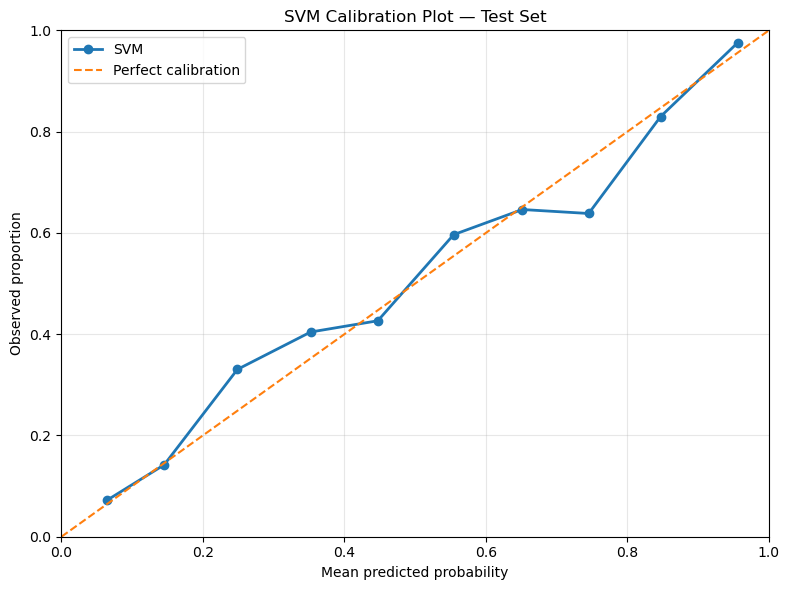

In [53]:
# ============================================================
# SVM — TEST SET CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Test predicted probabilities
y_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10,
    strategy='uniform'
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2,
    label='SVM'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Perfect calibration'
)

plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion')
plt.title('SVM Calibration Plot — Test Set')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

# logistic regresion

In [109]:
# ============================================================
# LOGISTIC REGRESSION — MODEL DEFINITION
# ============================================================

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

print(logreg)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                   solver='liblinear')


In [110]:
# ============================================================
# LOGISTIC REGRESSION — FIT MODEL ON TRAINING DATA
# ============================================================

logreg.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


In [111]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER SEARCH SPACE
# ============================================================

logreg_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

print("Logistic Regression hyperparameter search space:")
print(logreg_param_grid)

Logistic Regression hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100]}


In [112]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER OPTIMIZATION
#              TRAIN → VALIDATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

logreg_results = []

for C_value in logreg_param_grid['C']:

    logreg_candidate = LogisticRegression(
        penalty='l2',
        solver='liblinear',
        C=C_value,
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    )

    # Fit on training data
    logreg_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = logreg_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    logreg_results.append({
        'C': C_value,
        'Validation_ROC_AUC': validation_auc
    })

# Convert results to DataFrame
logreg_results_df = pd.DataFrame(logreg_results)

# Rank by validation ROC-AUC
logreg_results_df = logreg_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)

print("Logistic Regression hyperparameter tuning results:")
print(logreg_results_df)

# Best hyperparameter
best_logreg_C = logreg_results_df.loc[0, 'C']

print("\nBest Logistic Regression hyperparameter:")
print("C:", best_logreg_C)
print(
    "Validation ROC-AUC:",
    f"{logreg_results_df.loc[0, 'Validation_ROC_AUC']:.4f}"
)

Logistic Regression hyperparameter tuning results:
        C  Validation_ROC_AUC
0    0.10            0.838263
1    0.01            0.838073
2    1.00            0.838042
3   10.00            0.837944
4  100.00            0.837931

Best Logistic Regression hyperparameter:
C: 0.1
Validation ROC-AUC: 0.8383


In [113]:
# ============================================================
# LOGISTIC REGRESSION — CREATE AND FIT BEST MODEL
# ============================================================

from sklearn.linear_model import LogisticRegression

best_logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=best_logreg_C,
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

# Fit best model on training data
best_logreg.fit(
    X_train_scaled,
    y_train
)

print("Best Logistic Regression model fitted successfully.")
print("Best C:", best_logreg_C)

Best Logistic Regression model fitted successfully.
Best C: 0.1


In [114]:
# ============================================================
# LOGISTIC REGRESSION — VALIDATION SET PREDICTIONS
# ============================================================

logreg_validation_y_pred = best_logreg.predict(
    X_validation_scaled
)

# Probability of mortality
logreg_validation_y_prob = best_logreg.predict_proba(
    X_validation_scaled
)[:, 1]

print("Validation predictions generated successfully.")

Validation predictions generated successfully.


In [115]:
# ============================================================
# LOGISTIC REGRESSION — FINAL TEST SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)


# ============================================================
# TRAINING-SET AUROC
# ============================================================

logreg_train_y_prob = best_logreg.predict_proba(
    X_train_scaled
)[:, 1]

logreg_train_roc_auc = roc_auc_score(
    y_train,
    logreg_train_y_prob
)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

logreg_test_y_pred = best_logreg.predict(
    X_test_scaled
)

logreg_test_y_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# TEST-SET METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    logreg_test_y_pred
)

test_precision = precision_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

# Sensitivity = Recall
test_sensitivity = test_recall


# ============================================================
# SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    logreg_test_y_pred
).ravel()

test_specificity = tn / (tn + fp)


# ============================================================
# F1-SCORE
# ============================================================

test_f1 = f1_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)


# ============================================================
# TEST ROC-AUC
# ============================================================

test_roc_auc = roc_auc_score(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# BRIER SCORE — TEST SET
# ============================================================

test_brier_score = brier_score_loss(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# AUROC GAP
# ============================================================

logreg_auc_gap = (
    logreg_train_roc_auc - test_roc_auc
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\nLogistic Regression Performance")
print("=" * 60)

print(f"Training AUROC: {logreg_train_roc_auc:.4f}")
print(f"Test AUROC:     {test_roc_auc:.4f}")
print(f"AUROC Gap:      {logreg_auc_gap:.4f}")


print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {test_accuracy:.4f}")
print(f"Precision:      {test_precision:.4f}")
print(f"Sensitivity:    {test_sensitivity:.4f}")
print(f"Specificity:    {test_specificity:.4f}")
print(f"F1-score:       {test_f1:.4f}")
print(f"Brier Score:    {test_brier_score:.4f}")


print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        logreg_test_y_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


Logistic Regression Performance
Training AUROC: 0.8264
Test AUROC:     0.7941
AUROC Gap:      0.0323

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.7162
Precision:      0.6239
Sensitivity:    0.6801
Specificity:    0.7391
F1-score:       0.6508
Brier Score:    0.1829

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.7841    0.7391    0.7609       506
        Died     0.6239    0.6801    0.6508       322

    accuracy                         0.7162       828
   macro avg     0.7040    0.7096    0.7059       828
weighted avg     0.7218    0.7162    0.7181       828



# Model comparision

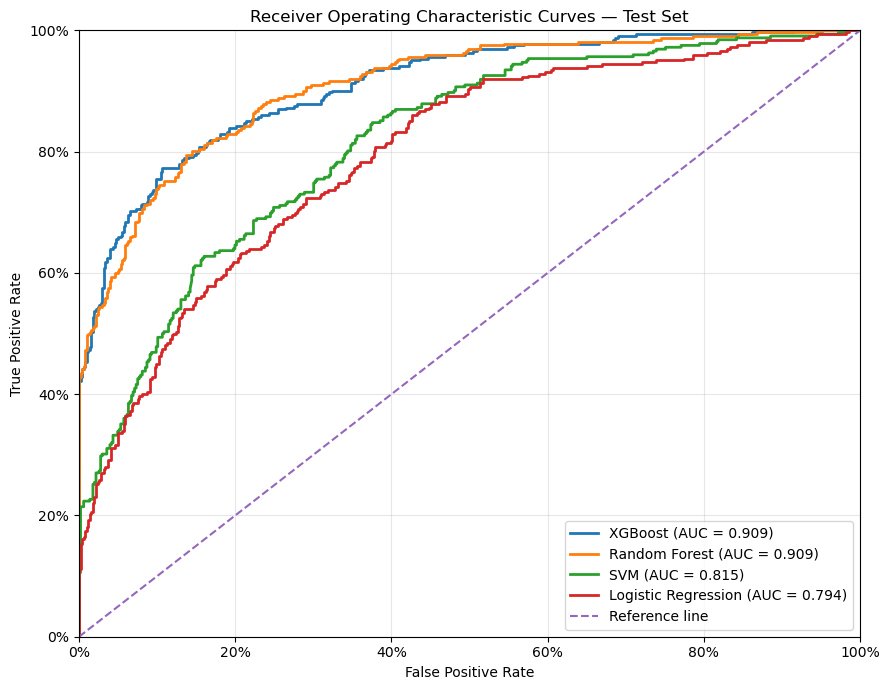

In [61]:
# ============================================================
# TEST-SET ROC CURVES — ALL FOUR FINAL MODELS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.ticker import PercentFormatter


# ============================================================
# XGBOOST
# ============================================================

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_test_prob
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)


# ============================================================
# RANDOM FOREST
# ============================================================

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_test_prob
)

rf_auc = roc_auc_score(
    y_test,
    rf_test_prob
)


# ============================================================
# SVM
# ============================================================

svm_fpr, svm_tpr, _ = roc_curve(
    y_test,
    y_test_prob
)

svm_auc = roc_auc_score(
    y_test,
    y_test_prob
)


# ============================================================
# LOGISTIC REGRESSION
# ============================================================

lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    logreg_test_y_prob
)

lr_auc = roc_auc_score(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    svm_fpr,
    svm_tpr,
    linewidth=2,
    label=f"SVM (AUC = {svm_auc:.3f})"
)

plt.plot(
    lr_fpr,
    lr_tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)


# ============================================================
# REFERENCE LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Reference line"
)


# ============================================================
# 0–100% AXES
# ============================================================

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.gca().xaxis.set_major_formatter(
    PercentFormatter(1)
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1)
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Receiver Operating Characteristic Curves — Test Set"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# FINAL TEST-SET MODEL EVALUATION COMPARISON
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# LOGISTIC REGRESSION
# ============================================================

logreg_test_pred = best_logreg.predict(X_test_scaled)

logreg_test_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]

logreg_accuracy = accuracy_score(
    y_test, logreg_test_pred
)

logreg_precision = precision_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_recall = recall_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_f1 = f1_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_auc = roc_auc_score(
    y_test, logreg_test_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_test, logreg_test_pred
).ravel()

logreg_specificity = tn / (tn + fp)


# ============================================================
# XGBOOST — SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test, xgb_test_pred
).ravel()

xgb_specificity = tn / (tn + fp)


# ============================================================
# RANDOM FOREST
# ============================================================

# Already calculated in your RF code:
# rf_test_accuracy
# rf_test_precision
# rf_test_sensitivity
# rf_test_specificity
# rf_test_f1
# rf_test_roc_auc


# ============================================================
# SVM
# ============================================================

# Already calculated in your SVM code:
# accuracy
# precision
# sensitivity
# specificity
# f1
# roc_auc


# ============================================================
# CREATE FINAL COMPARISON TABLE
# ============================================================

model_comparison = pd.DataFrame({

    "Model": [
        "XGBoost",
        "Random Forest",
        "SVM",
        "Logistic Regression"
    ],

    "Accuracy": [
        xgb_test_accuracy,
        rf_test_accuracy,
        accuracy,
        logreg_accuracy
    ],

    "Precision": [
        xgb_test_precision,
        rf_test_precision,
        precision,
        logreg_precision
    ],

    "Recall (Sensitivity)": [
        xgb_test_sensitivity,
        rf_test_sensitivity,
        sensitivity,
        logreg_recall
    ],

    "Specificity": [
        xgb_specificity,
        rf_test_specificity,
        specificity,
        logreg_specificity
    ],

    "AUROC": [
        xgb_test_roc_auc,
        rf_test_roc_auc,
        roc_auc,
        logreg_auc
    ],

    "F1-score": [
        xgb_test_f1,
        rf_test_f1,
        f1,
        logreg_f1
    ]
})


# ============================================================
# DISPLAY RESULTS
# ============================================================

display(
    model_comparison.round(3)
)

,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,AUROC,F1-score
0,XGBoost,0.841,0.808,0.773,0.883,0.909,0.790
1,Random Forest,0.836,0.839,0.714,0.913,0.909,0.772
2,SVM,0.738,0.665,0.658,0.789,0.815,0.661
3,Logistic Regression,0.716,0.624,0.680,0.739,0.794,0.651


In [117]:
# ============================================================
# VALIDATION-SET MODEL PERFORMANCE COMPARISON
# ============================================================

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# LOGISTIC REGRESSION — VALIDATION PERFORMANCE
# ============================================================

logreg_validation_pred = best_logreg.predict(
    X_validation_scaled
)

logreg_validation_prob = best_logreg.predict_proba(
    X_validation_scaled
)[:, 1]

logreg_validation_accuracy = accuracy_score(
    y_validation, logreg_validation_pred
)

logreg_validation_precision = precision_score(
    y_validation, logreg_validation_pred, zero_division=0
)

logreg_validation_recall = recall_score(
    y_validation, logreg_validation_pred, zero_division=0
)

logreg_validation_f1 = f1_score(
    y_validation, logreg_validation_pred, zero_division=0
)

logreg_validation_auc = roc_auc_score(
    y_validation, logreg_validation_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    logreg_validation_pred,
    labels=[0, 1]
).ravel()

logreg_validation_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)


# ============================================================
# XGBOOST — VALIDATION PERFORMANCE
# ============================================================

xgb_validation_pred = xgb_model.predict(
    X_validation_processed
)

xgb_validation_prob = xgb_model.predict_proba(
    X_validation_processed
)[:, 1]

xgb_validation_accuracy = accuracy_score(
    y_validation, xgb_validation_pred
)

xgb_validation_precision = precision_score(
    y_validation, xgb_validation_pred, zero_division=0
)

xgb_validation_sensitivity = recall_score(
    y_validation, xgb_validation_pred, zero_division=0
)

xgb_validation_f1 = f1_score(
    y_validation, xgb_validation_pred, zero_division=0
)

xgb_validation_auc = roc_auc_score(
    y_validation, xgb_validation_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    xgb_validation_pred,
    labels=[0, 1]
).ravel()

xgb_validation_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)


# ============================================================
# RANDOM FOREST — VALIDATION PERFORMANCE
# ============================================================

rf_validation_pred = rf_model.predict(
    X_validation_processed
)

rf_validation_prob = rf_model.predict_proba(
    X_validation_processed
)[:, 1]

rf_validation_accuracy = accuracy_score(
    y_validation, rf_validation_pred
)

rf_validation_precision = precision_score(
    y_validation, rf_validation_pred, zero_division=0
)

rf_validation_sensitivity = recall_score(
    y_validation, rf_validation_pred, zero_division=0
)

rf_validation_f1 = f1_score(
    y_validation, rf_validation_pred, zero_division=0
)

rf_validation_auc = roc_auc_score(
    y_validation, rf_validation_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    rf_validation_pred,
    labels=[0, 1]
).ravel()

rf_validation_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)


# ============================================================
# SVM — VALIDATION PERFORMANCE
# ============================================================

svm_validation_pred = svm_final_model.predict(
    X_validation_scaled
)

svm_validation_prob = svm_final_model.predict_proba(
    X_validation_scaled
)[:, 1]

svm_validation_accuracy = accuracy_score(
    y_validation, svm_validation_pred
)

svm_validation_precision = precision_score(
    y_validation, svm_validation_pred, zero_division=0
)

svm_validation_sensitivity = recall_score(
    y_validation, svm_validation_pred, zero_division=0
)

svm_validation_f1 = f1_score(
    y_validation, svm_validation_pred, zero_division=0
)

svm_validation_auc = roc_auc_score(
    y_validation, svm_validation_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    svm_validation_pred,
    labels=[0, 1]
).ravel()

svm_validation_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)


# ============================================================
# CREATE VALIDATION PERFORMANCE COMPARISON TABLE
# ============================================================

validation_model_comparison = pd.DataFrame({

    "Model": [
        "XGBoost",
        "Random Forest",
        "SVM",
        "Logistic Regression"
    ],

    "Accuracy": [
        xgb_validation_accuracy,
        rf_validation_accuracy,
        svm_validation_accuracy,
        logreg_validation_accuracy
    ],

    "Precision": [
        xgb_validation_precision,
        rf_validation_precision,
        svm_validation_precision,
        logreg_validation_precision
    ],

    "Recall (Sensitivity)": [
        xgb_validation_sensitivity,
        rf_validation_sensitivity,
        svm_validation_sensitivity,
        logreg_validation_recall
    ],

    "Specificity": [
        xgb_validation_specificity,
        rf_validation_specificity,
        svm_validation_specificity,
        logreg_validation_specificity
    ],

    "AUROC": [
        xgb_validation_auc,
        rf_validation_auc,
        svm_validation_auc,
        logreg_validation_auc
    ],

    "F1-score": [
        xgb_validation_f1,
        rf_validation_f1,
        svm_validation_f1,
        logreg_validation_f1
    ]
})


# ============================================================
# DISPLAY VALIDATION RESULTS
# ============================================================

print("\nVALIDATION-SET MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(validation_model_comparison.round(4))


VALIDATION-SET MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,AUROC,F1-score
0,XGBoost,0.8549,0.7988,0.8385,0.8653,0.9376,0.8182
1,Random Forest,0.8489,0.8127,0.7950,0.8832,0.9349,0.8038
2,SVM,0.7751,0.6868,0.7764,0.7743,0.8519,0.7289
3,Logistic Regression,0.7594,0.6623,0.7795,0.7465,0.8383,0.7161
